# Final Project: CCDB June-2026 Report

## Set Up

Libraries, settings, the data file's path, and `check()`, the helper that prints a PASS/FAIL line for every check in the notebook.

In [1]:
# --- Setup ---------------------------------------------------------------
# Libraries, settings, the data path and the check() helper used across the notebook.
import hashlib
import sys
import textwrap
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import pandas as pd

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)

# Paths resolve from the project root, so the notebook runs on either partner's machine
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_DIR / "data" / "raw" / "CCDB_Export_19_June_2026.zip"


def check(name, passed, detail=""):
    """Print one PASS/FAIL line for a named check; returns whether it passed."""
    print(f"{'PASS' if passed else 'FAIL'}  {name}  {detail}")
    return passed


print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| matplotlib:", matplotlib.__version__)
assert DATA_PATH.exists(), f"Data file not found: {DATA_PATH}"

Python: 3.12.10
pandas: 3.0.5 | numpy: 2.5.3 | matplotlib: 3.11.1


## Load Data

The CFPB Consumer Complaint Database export of complaints received in June 2026 (source and download steps in `data/README.md`). Every column is read as text, so types change only in Clean.

In [2]:
# --- Load data -----------------------------------------------------------
# Fingerprint of the June 2026 export, recorded when we first profiled it (2026-10-24).
# A different value means the file is not the one we profiled, so stop before reading it.
EXPECTED_SHA256 = "3021c8af9eeed4971a92f15be21c7ce08cf3c1337151de255e5b12bf782049df"
actual_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert check("file fingerprint matches the profiled export", actual_sha256 == EXPECTED_SHA256,
             f"(expected {EXPECTED_SHA256[:12]}..., actual {actual_sha256[:12]}...)"), "Wrong data file; do not continue"

# Read every column as text; types get converted on purpose in Clean
df_raw = pd.read_csv(DATA_PATH, dtype=str)

EXPECTED_COLS = [
    "Date received", "Product", "Sub-product", "Issue", "Sub-issue",
    "Consumer complaint narrative", "Company public response", "Company",
    "State", "ZIP code", "Tags", "Submitted via", "Date sent to company",
    "Company response to consumer", "Timely response?", "Complaint ID",
]
results = [
    check(f"{len(EXPECTED_COLS)} columns in the expected order", list(df_raw.columns) == EXPECTED_COLS),
    check("row count", len(df_raw) == 620_794, f"(expected 620,794, actual {len(df_raw):,})"),
    check("Complaint ID is unique", df_raw["Complaint ID"].is_unique),
]
assert all(results), "A load check failed; see the FAIL lines above"

print(f"\nLoaded {len(df_raw):,} rows x {df_raw.shape[1]} columns "
      f"({df_raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory)")

# Preview without the narrative column to keep the output short
df_raw.drop(columns=["Consumer complaint narrative"]).head(3)

PASS  file fingerprint matches the profiled export  (expected 3021c8af9eee..., actual 3021c8af9eee...)
PASS  16 columns in the expected order  
PASS  row count  (expected 620,794, actual 620,794)
PASS  Complaint ID is unique  

Loaded 620,794 rows x 16 columns (670 MB in memory)


,Date received,Product,Sub-product,Issue,Sub-issue,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
0,2026-06-07,Credit card,General-purpose credit card or charge card,Closing your account,Company closed your account,NaN,OneMain Finance Corporation,TN,37087,NaN,Web,2026-06-07,Closed with explanation,Yes,22972138
1,2026-06-06,Credit reporting or other personal consumer reports,Credit reporting,Improper use of your report,Credit inquiries on your report that you don't recognize,NaN,"EQUIFAX, INC.",MI,48221,NaN,Web,2026-06-06,Closed with explanation,Yes,22960234
2,2026-06-02,Debt collection,Other debt,Electronic communications,"You told them to stop contacting you, but they keep trying",NaN,"Landmark Strategy Group, LLC",NC,28278,NaN,Web,2026-08-28,Untimely response,No,22819786


## Explore

What the export contains, and the evidence behind three decisions: which complaints the models can read, what they predict, and which copies to drop.
- **Structure, Value Counts, Raw Data Dictionary:** every column of the full export profiled.
- **Narrative Subset:** the complaints with a narrative, the only ones a language model can read, compared with the full export.
- **Target Candidates:** four possible targets; relief is set aside and Issue is chosen.
- **Duplicate Narratives:** repeated and scripted texts, and the rule for removing them.

### Structure

Dimensions, data types, missingness and uniqueness for every column, computed directly from the raw export. Everything here is read off the data; no outside assumptions.

In [3]:
# --- Profile: structure ----------------------------------------------------
n_rows, n_cols = df_raw.shape
print(f"Dimensions: {n_rows:,} rows x {n_cols} columns")

profile = pd.DataFrame({
    "dtype":     df_raw.dtypes.astype(str),
    "non_null":  df_raw.notna().sum(),
    "null_n":    df_raw.isna().sum(),
    "null_%":    (100 * df_raw.isna().mean()).round(1),
    "n_unique":  df_raw.nunique(),
    "unique_%":  (100 * df_raw.nunique() / n_rows).round(2),
})

display(profile)

Dimensions: 620,794 rows x 16 columns


,dtype,non_null,null_n,null_%,n_unique,unique_%
Date received,str,620794,0,0.0,30,0.00
Product,str,620794,0,0.0,11,0.00
Sub-product,str,620794,0,0.0,55,0.01
Issue,str,620794,0,0.0,85,0.01
Sub-issue,str,613772,7022,1.1,208,0.03
Consumer complaint narrative,str,16820,603974,97.3,15380,2.48
Company public response,str,389489,231305,37.3,9,0.00
Company,str,620794,0,0.0,1831,0.29
State,str,620223,571,0.1,60,0.01
ZIP code,str,620329,465,0.1,14756,2.38


### Value Counts

How often each value appears in the category columns: the options a consumer picks when filing (Product, Sub-product, Issue, Sub-issue) and the other fixed-value fields (Company, State, Tags, how the complaint was submitted, how the company responded). Complaint ID, the dates, ZIP code and the narrative are skipped; the narrative gets its own sections later.

Columns with up to 15 values are listed in full, the rest show their top 10; missing values appear as `NaN`.

In [4]:
# --- Profile: value counts -------------------------------------------------
SKIP_COLS = ["Complaint ID", "Consumer complaint narrative",   # identifier, free text
             "Date received", "Date sent to company",          # dates: covered in Structure and Clean
             "ZIP code"]                                       # location code, not a category
FULL_LIST_MAX = 15  # list every value when a column has at most this many
TOP_N = 10

for col in df_raw.columns.drop(SKIP_COLS):
    vc = df_raw[col].value_counts(dropna=False)
    n_distinct = int(profile.loc[col, "n_unique"])  # int() tells VS Code this is a whole number (else it flags the <= below)
    shown = vc if n_distinct <= FULL_LIST_MAX else vc.head(TOP_N)
    label = "all values" if n_distinct <= FULL_LIST_MAX else f"top {TOP_N} of {n_distinct:,}"

    print(f"\n=== {col} ({label}) ===")
    for value, count in shown.items():
        print(f"  {str(value)[:60]:60} {count:>9,}  {100 * count / n_rows:5.1f}%")


=== Product (all values) ===
  Credit reporting or other personal consumer reports            565,831   91.1%
  Debt collection                                                 27,629    4.5%
  Checking or savings account                                      7,671    1.2%
  Credit card                                                      7,453    1.2%
  Money transfer, virtual currency, or money service               3,037    0.5%
  Mortgage                                                         2,967    0.5%
  Vehicle loan or lease                                            2,002    0.3%
  Student loan                                                     1,724    0.3%
  Payday loan, title loan, personal loan, or advance loan          1,588    0.3%
  Prepaid card                                                       523    0.1%
  Debt or credit management                                          369    0.1%

=== Sub-product (top 10 of 55) ===
  Credit reporting                         

### Raw Data Dictionary

One row per raw column. Sources for each part:
- `role`, `observed`: from the Structure and Value Counts output above.
- `null_%`, `n_unique`: pulled from the `profile` table, not typed by hand.
- `cfpb_description`: quoted from the CFPB page *How we share complaint data*, table "What we publish in the Consumer Complaint Database" (https://www.consumerfinance.gov/complaint/data-use/, page last updated 2026-09-14, filtered for June, 2026). The page does not describe the narrative field.
- `cleaning_action`: our proposed treatment (a judgment call, to be confirmed in the Clean section).

In [5]:
# --- Data dictionary -------------------------------------------------------
NOT_DESCRIBED = "Not described on the CFPB data-use page"

FIELD_NOTES = {
    "Date received": {
        "role": "date",
        "cfpb_description": "The date the CFPB received the complaint.",
        "observed": "30 distinct dates; stored as YYYY-MM-DD text",
        "cleaning_action": "Convert to datetime",
    },
    "Product": {
        "role": "category",
        "cfpb_description": "The type of product the consumer identified in the complaint.",
        "observed": "11 values; credit reporting is 91.1% of rows",
        "cleaning_action": "Keep as category",
    },
    "Sub-product": {
        "role": "category",
        "cfpb_description": "The type of sub-product the consumer identified in the complaint.",
        "observed": "55 values; 'I do not know' in 18,577 rows (3.0%)",
        "cleaning_action": "Keep as category; decide whether 'I do not know' counts as missing",
    },
    "Issue": {
        "role": "category",
        "cfpb_description": "The issue the consumer identified in the complaint.",
        "observed": "85 values; top 3 (all credit reporting) cover 90.6%",
        "cleaning_action": "Keep as category",
    },
    "Sub-issue": {
        "role": "category",
        "cfpb_description": "The sub-issue the consumer identified in the complaint.",
        "observed": "208 values; 1.1% missing",
        "cleaning_action": "Keep as category",
    },
    "Consumer complaint narrative": {
        "role": "text",
        "cfpb_description": NOT_DESCRIBED,
        "observed": "Filled in 2.7% of rows; 15,380 unique texts out of 16,820 (repeats exist)",
        "cleaning_action": "Decide after the use case is chosen (duplicates, length)",
    },
    "Company public response": {
        "role": "category",
        "cfpb_description": "The company's optional, public-facing response to a consumer's complaint.",
        "observed": "9 values; 37.3% missing; one fixed text covers 62.2%",
        "cleaning_action": "Read the full text of the 62.2% value, then decide how to recode",
    },
    "Company": {
        "role": "category",
        "cfpb_description": "The complaint is about this company.",
        "observed": "1,831 companies; the three largest cover 88.7%",
        "cleaning_action": "Keep as category",
    },
    "State": {
        "role": "geo",
        "cfpb_description": "The state of the mailing address provided by the consumer.",
        "observed": "60 values (more than 50 states + DC); 0.1% missing",
        "cleaning_action": "Inspect the codes beyond the 50 states + DC",
    },
    "ZIP code": {
        "role": "geo",
        "cfpb_description": "The mailing ZIP code provided by the consumer.",
        "observed": "465 blank plus 1,694 'XXXXX' (masking not documented as XXXXX)",
        "cleaning_action": "Keep as text; treat 'XXXXX' as missing",
    },
    "Tags": {
        "role": "flag",
        "cfpb_description": "Data that supports easier searching and sorting of complaints "
                            "submitted by or on behalf of consumers.",
        "observed": "97.8% missing; 758 rows combine 'Older American, Servicemember'",
        "cleaning_action": "Split into two yes/no flags",
    },
    "Submitted via": {
        "role": "category",
        "cfpb_description": "How the complaint was submitted to the CFPB.",
        "observed": "4 values; Web is 99.5%",
        "cleaning_action": "Keep; little variation",
    },
    "Date sent to company": {
        "role": "date",
        "cfpb_description": "The date the CFPB sent the complaint to the company.",
        "observed": "80 distinct dates (vs. 30 for Date received)",
        "cleaning_action": "Convert to datetime",
    },
    "Company response to consumer": {
        "role": "category",
        "cfpb_description": "This is how the company responded.",
        "observed": "5 values; monetary relief 0.5%; 448 'In progress'",
        "cleaning_action": "Candidate outcome label; 'In progress' has no final outcome yet",
    },
    "Timely response?": {
        "role": "flag",
        "cfpb_description": "Whether the company gave a timely response.",
        "observed": "Yes/No; 3,139 'No' vs. 2,233 'Untimely response' in the column above",
        "cleaning_action": "Convert to boolean; crosstab against Company response to consumer",
    },
    "Complaint ID": {
        "role": "id",
        "cfpb_description": "The unique identification number for a complaint.",
        "observed": "Unique for all 620,794 rows",
        "cleaning_action": "Keep as text key",
    },
}
assert list(FIELD_NOTES) == list(df_raw.columns), "Dictionary doesn't match the raw columns (names or order)"

data_dict = pd.DataFrame.from_dict(FIELD_NOTES, orient="index")
data_dict.insert(1, "null_%", profile["null_%"])
data_dict.insert(2, "n_unique", profile["n_unique"])
data_dict.index.name = "column"

with pd.option_context("display.max_colwidth", 120):
    display(data_dict)

,role,null_%,n_unique,cfpb_description,observed,cleaning_action
column,,,,,,
Date received,date,0.0,30,The date the CFPB received the complaint.,30 distinct dates; stored as YYYY-MM-DD text,Convert to datetime
Product,category,0.0,11,The type of product the consumer identified in the complaint.,11 values; credit reporting is 91.1% of rows,Keep as category
Sub-product,category,0.0,55,The type of sub-product the consumer identified in the complaint.,"55 values; 'I do not know' in 18,577 rows (3.0%)",Keep as category; decide whether 'I do not know' counts as missing
Issue,category,0.0,85,The issue the consumer identified in the complaint.,85 values; top 3 (all credit reporting) cover 90.6%,Keep as category
Sub-issue,category,1.1,208,The sub-issue the consumer identified in the complaint.,208 values; 1.1% missing,Keep as category
Consumer complaint narrative,text,97.3,15380,Not described on the CFPB data-use page,"Filled in 2.7% of rows; 15,380 unique texts out of 16,820 (repeats exist)","Decide after the use case is chosen (duplicates, length)"
Company public response,category,37.3,9,"The company's optional, public-facing response to a consumer's complaint.",9 values; 37.3% missing; one fixed text covers 62.2%,"Read the full text of the 62.2% value, then decide how to recode"
Company,category,0.0,1831,The complaint is about this company.,"1,831 companies; the three largest cover 88.7%",Keep as category
State,geo,0.1,60,The state of the mailing address provided by the consumer.,60 values (more than 50 states + DC); 0.1% missing,Inspect the codes beyond the 50 states + DC


### Narrative Subset

Only complaints with a consumer narrative can be read by a language model, so check how that subset compares with the full export.

In [6]:
# --- Explore: narrative subset vs. all complaints --------------------------
NARRATIVE_COL = "Consumer complaint narrative"
has_narrative = df_raw[NARRATIVE_COL].fillna("").str.strip() != ""
df_narrative = df_raw[has_narrative]
print(f"Complaints with a narrative: {has_narrative.sum():,} of {len(df_raw):,} ({has_narrative.mean():.1%})")

# Product mix in each population, and how often each product's complaints include a narrative
by_product = pd.DataFrame({
    "all_n": df_raw["Product"].value_counts(),
    "narrative_n": df_narrative["Product"].value_counts(),
})
by_product["all_%"] = 100 * by_product["all_n"] / by_product["all_n"].sum()
by_product["narrative_%"] = 100 * by_product["narrative_n"] / by_product["narrative_n"].sum()
by_product["has_narrative_%"] = 100 * by_product["narrative_n"] / by_product["all_n"]  # narratives / all complaints
by_product = (by_product[["all_n", "all_%", "narrative_n", "narrative_%", "has_narrative_%"]]
              .sort_values("narrative_n", ascending=False))

results = [
    check("all-complaint shares add to 100%", np.isclose(by_product["all_%"].sum(), 100),
          f"({by_product['all_%'].sum():.1f}%)"),
    check("narrative shares add to 100%", np.isclose(by_product["narrative_%"].sum(), 100),
          f"({by_product['narrative_%'].sum():.1f}%)"),
]
assert all(results), "A share check failed; see the FAIL lines above"
display(by_product.round({"all_%": 1, "narrative_%": 1, "has_narrative_%": 2}))

Complaints with a narrative: 16,820 of 620,794 (2.7%)
PASS  all-complaint shares add to 100%  (100.0%)
PASS  narrative shares add to 100%  (100.0%)


,all_n,all_%,narrative_n,narrative_%,has_narrative_%
Product,,,,,
Debt collection,27629,4.5,5098,30.3,18.45
Checking or savings account,7671,1.2,3270,19.4,42.63
Credit card,7453,1.2,2840,16.9,38.11
"Money transfer, virtual currency, or money service",3037,0.5,1340,8.0,44.12
Mortgage,2967,0.5,1151,6.8,38.79
Vehicle loan or lease,2002,0.3,793,4.7,39.61
Credit reporting or other personal consumer reports,565831,91.1,751,4.5,0.13
"Payday loan, title loan, personal loan, or advance loan",1588,0.3,636,3.8,40.05
Student loan,1724,0.3,576,3.4,33.41


#### Chart: Product Mix, All Complaints vs. Narratives

The table above as a picture: the narrative subset has a very different product mix from the full export. One row per product, with its share of all complaints and its share of narratives, joined by a line. Same base as the table above (all rows, including 'In progress').

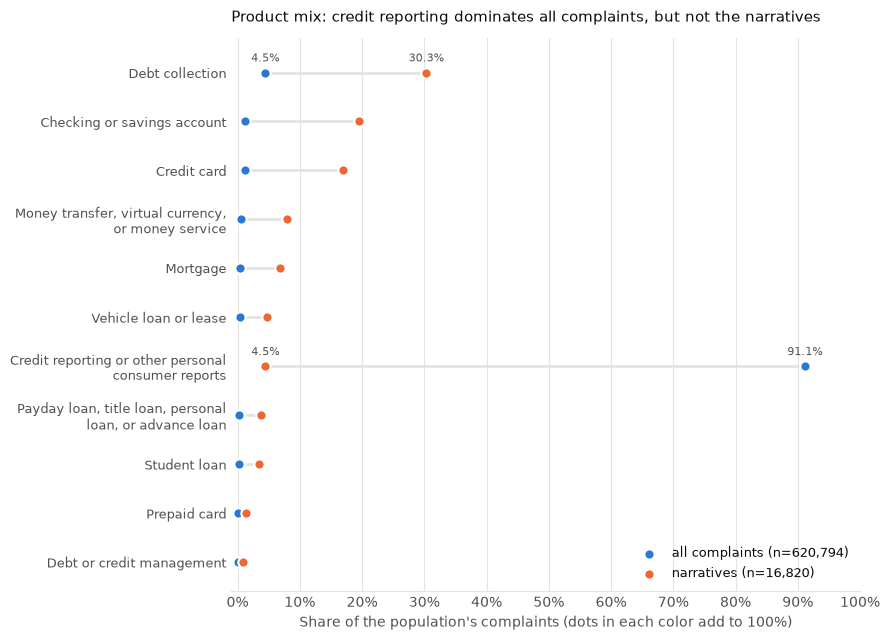

In [7]:
# --- Chart: product mix, all complaints vs. narratives ----------------------
# Chart colors for every chart in the notebook: blue = all complaints, orange = narratives
# (a colorblind-safe pair), plus grays for text and gridlines
POP_COLORS = {"all complaints": "#2a78d6", "narratives": "#eb6834"}
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

# Plot: products sorted by narrative share, highest at the top
mix = by_product.sort_values("narrative_%")
y = np.arange(len(mix))

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.hlines(y, mix["all_%"], mix["narrative_%"], color=GRID, lw=2, zorder=1)
for col, name in [("all_%", "all complaints"), ("narrative_%", "narratives")]:
    total = mix[col.replace("%", "n")].sum()
    ax.scatter(mix[col], y, s=55, color=POP_COLORS[name], edgecolor="white", linewidth=1.5, zorder=3,
               label=f"{name} (n={total:,})")

# Direct labels on the two products that move the most
for product in ["Credit reporting or other personal consumer reports", "Debt collection"]:
    row = y[mix.index.get_loc(product)]
    for col in ["all_%", "narrative_%"]:
        ax.annotate(f"{mix.loc[product, col]:.1f}%", (mix.loc[product, col], row), xytext=(0, 8),
                    textcoords="offset points", ha="center", fontsize=8, color=INK_MUTED)

ax.set_yticks(y, [textwrap.fill(p, 34) for p in mix.index], fontsize=9, color=INK)
ax.set_ylim(-0.6, len(mix) - 0.3)
ax.set_xlim(-1, 100)
ax.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(10))
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(decimals=0))
ax.set_xlabel("Share of the population's complaints (dots in each color add to 100%)", color=INK_MUTED)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=INK_MUTED, length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.legend(loc="lower right", frameon=False, fontsize=9, labelcolor=INK)
ax.set_title("Product mix: credit reporting dominates all complaints, but not the narratives",
             loc="left", fontsize=11, color=INK, pad=12)
fig.tight_layout()
plt.show()

**How to read the chart**

Think of it as two pie charts drawn as dots, with one row per product:
- **Blue dot:** the product's share of all 620,794 complaints (the product mix of the full export).
- **Orange dot:** the product's share of the 16,820 narratives (the product mix of the narrative subset).
- **Each color adds to 100%** across the 11 products, so when one product's share shrinks, the others must grow.
- **Gray line:** the gap between the two shares. The longer the line, the more the narratives over- or under-represent that product.

*Example:* credit card has fewer narratives than complaints (2,840 vs. 7,453), as a subset must. But it is a bigger slice of a much smaller pie: 16.9% of narratives vs. 1.2% of all complaints.

**What it shows**

1. **Credit reporting nearly disappears:** 91.1% of all complaints, but 4.5% of narratives.
2. **Debt collection becomes the largest product:** 4.5% of all complaints, but 30.3% of narratives.
3. **Every other product gains share,** e.g. checking/savings 1.2% → 19.4% and credit card 1.2% → 16.9%.

**Why:** only 0.13% of credit-reporting complaints include a narrative (751 of 565,831), against 18.5% for debt collection, 33-44% for every other product, and 2.7% overall (`has_narrative_%` in the table above). The data does not say why.

**Implication:** the narratives are not a representative sample of the export. Anything learned from them, including the model, describes complaints led by debt collection, checking/savings and credit card, with very few about credit reporting. The same product mix explains why the overall relief rates of the two groups differ (Relief Patterns).

*Note:* shares here include complaints still 'In progress', so credit reporting reads 91.1% here vs. 91.2% of *closed* complaints in the relief charts.

### Target Candidates

Four columns could be the model's target, compared here within the narratives (the only complaints an LLM can read):
- **Company response to consumer** (relief): *how the complaint ended*, reported by the company. Evaluated first, in Candidate 1, and set aside.
- **Product, Sub-product, Issue:** *what the complaint is about*, picked by the consumer when filing. Evaluated in Candidates 2-4; **Issue is chosen**.

What the table measures:
- `classes_>=30` / `classes_>=100`: classes with enough narratives to score on their own.
- `classes_per_product`: how many options one product offers (Sub-product and Issue options depend on the product).
- `largest_%` / `top5_%`: how much the biggest classes dominate; a dominant class makes accuracy look high without meaning much.

In [8]:
# --- Explore: target candidates (narrative subset) --------------------------
TARGET_CANDIDATES = ["Company response to consumer", "Product", "Sub-product", "Issue"]  # in the order evaluated
MIN_CLASS_SMALL, MIN_CLASS_LARGE = 30, 100


def describe_target(col):
    """Class structure of one candidate target within the narrative subset."""
    vc = df_narrative[col].value_counts()
    per_product = df_narrative.groupby("Product")[col].nunique()
    return {
        "classes": len(vc),
        f"classes_>={MIN_CLASS_SMALL}": int((vc >= MIN_CLASS_SMALL).sum()),
        f"classes_>={MIN_CLASS_LARGE}": int((vc >= MIN_CLASS_LARGE).sum()),
        "classes_per_product": f"{per_product.min()}-{per_product.max()}",
        "largest_class": str(vc.index[0])[:45],
        "largest_%": round(100 * vc.iloc[0] / vc.sum(), 1),
        "top5_%": round(100 * vc.head(5).sum() / vc.sum(), 1),
    }


n_missing = int(df_narrative[TARGET_CANDIDATES].isna().sum().sum())
assert check("no missing labels in any candidate", n_missing == 0, f"(missing: {n_missing})")

targets = pd.DataFrame({col: describe_target(col) for col in TARGET_CANDIDATES}).T
display(targets)

PASS  no missing labels in any candidate  (missing: 0)


,classes,classes_>=30,classes_>=100,classes_per_product,largest_class,largest_%,top5_%
Company response to consumer,4,4,4,3-4,Closed with explanation,76.5,100.0
Product,11,11,11,1-1,Debt collection,30.3,81.4
Sub-product,52,37,26,2-11,Checking account,16.0,54.1
Issue,83,53,38,5-28,Attempts to collect debt not owed,13.7,40.8


#### Candidate 1: Relief Patterns

Could a model read a narrative and predict how the complaint ends (`Company response to consumer`)? This part describes which complaints end in relief, for all complaints and for the narratives; it fits no model. **Relief is set aside**; the four reasons are at the end of this part (*Why Relief Was Not Chosen as the Target*).

**What the response categories mean.** Companies "select the closure category that is supported by their actions and written response", one per complaint (CFPB, *2025 Consumer Response Annual Report*, published March 2026, section "Complaint response categories", pp. 12-13; https://files.consumerfinance.gov/f/documents/cfpb_2025-cr-annual-report_2026-03.pdf):
- *Closed with monetary relief*: "company reported providing objective, measurable, and verifiable monetary relief to the consumer as a direct result of the steps that have or will be taken in response to the complaint."
- *Closed with non-monetary relief*: "company reported providing other objective and verifiable relief to the consumer [...] (e.g., stopping unwanted calls from debt collectors; correcting account information; correcting inaccurate data provided or reported in a credit report; issuing corrected documents; restoring account access; and, addressing formerly unmet customer service issues)."
- *Closed with explanation*: "company reported that the complaint did not result in relief but provided a written explanation tailored to the issues raised by the consumer."

Two consequences for reading the rates: every category is *company-reported*, not verified by us, and the export has no dollar amounts. The quoted section does not define `Untimely response` or `In progress`; how we treat them below is our choice.

**How the rates are computed**
- **Monetary**, **non-monetary** and **any relief** (either of the two). Each complaint has one closure category, so monetary + non-monetary = any relief. The tables report monetary and any relief; the charts show monetary and non-monetary.
- `In progress` complaints have no final outcome and are excluded; `Untimely response` counts as closed without relief.
- Each rate has a 95% Wilson confidence interval (suited to small proportions).
- The company table ranks only companies with at least `MIN_GROUP_N` (100) complaints, so small ones can't top the list by chance.
- All rates are associations, not causes: a high rate says which complaints *tend* to end in relief, not why.

In [9]:
# --- Explore: relief patterns ----------------------------------------------
OUTCOME_COL = "Company response to consumer"
MONETARY = "Closed with monetary relief"
NON_MONETARY = "Closed with non-monetary relief"
MIN_GROUP_N = 100  # groups smaller than this are not ranked
TOP_N = 10
Z95 = 1.96


def wilson_ci(k, n, z=Z95):
    """95% Wilson score interval for the proportion k/n (works on arrays); returns (low, high)."""
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return center - half, center + half


def relief_table(df, by):
    """Monetary and any-relief rates per group with 95% CIs; 'In progress' complaints excluded."""
    closed = df[df[OUTCOME_COL] != "In progress"]
    grouped = closed.assign(
        monetary=closed[OUTCOME_COL].eq(MONETARY),
        any_relief=closed[OUTCOME_COL].isin([MONETARY, NON_MONETARY]),
    ).groupby(by)[["monetary", "any_relief"]]
    n = grouped.size()
    counts = grouped.sum()

    out = pd.DataFrame({"n": n})
    for name in ["monetary", "any_relief"]:
        low, high = wilson_ci(counts[name], n)
        out[f"{name}_%"] = (100 * counts[name] / n).round(1)
        out[f"{name}_95CI"] = [f"{100 * a:.1f}-{100 * b:.1f}" for a, b in zip(low, high)]
    return out


populations = {"all complaints": df_raw, "narratives": df_narrative}

# Overall baseline for each population
for name, df in populations.items():
    overall = relief_table(df.assign(_all="all"), "_all").iloc[0]
    print(f"{name:15} n={overall['n']:>8,}  monetary {overall['monetary_%']:4.1f}% ({overall['monetary_95CI']})  "
          f"any relief {overall['any_relief_%']:4.1f}% ({overall['any_relief_95CI']})")

# 1. Product: both populations side by side
by_product_relief = pd.concat({name: relief_table(df, "Product") for name, df in populations.items()}, axis=1)
display(by_product_relief.sort_values(("all complaints", "monetary_%"), ascending=False))

# 2. Company (narratives): top groups by monetary rate among companies with n >= MIN_GROUP_N
company = relief_table(df_narrative, "Company")
eligible = company[company["n"] >= MIN_GROUP_N]
print(f"\nCompany | narratives: top {TOP_N} by monetary relief "
      f"({len(eligible)} of {len(company)} companies have n >= {MIN_GROUP_N})")
display(eligible.sort_values("monetary_%", ascending=False).head(TOP_N))

all complaints  n= 620,346  monetary  0.5% (0.4-0.5)  any relief 35.2% (35.1-35.3)
narratives      n=  16,820  monetary  7.1% (6.7-7.5)  any relief 20.6% (20.0-21.2)


all complaints  \
                                                                     n   
Product                                                                  
Credit card                                                       7380   
Checking or savings account                                       7637   
Prepaid card                                                       521   
Money transfer, virtual currency, or money service                3025   
Payday loan, title loan, personal loan, or advance loan           1550   
Debt or credit management                                          362   
Vehicle loan or lease                                             1992   
Mortgage                                                          2940   
Student loan                                                      1712   
Debt collection                                                  27502   
Credit reporting or other personal consumer reports             565725   

                                                                    \
                                                        monetary_%   
Product                                                              
Credit card                                                   16.5   
Checking or savings account                                   13.4   
Prepaid card                                                  12.9   
Money transfer, virtual currency, or money service             9.2   
Payday loan, title loan, personal loan, or advance loan        3.3   
Debt or credit management                                      3.3   
Vehicle loan or lease                                          2.2   
Mortgage                                                       1.8   
Student loan                                                   0.4   
Debt collection                                                0.2   
Credit reporting or other personal consumer reports            0.0   

                                                                       \
                                                        monetary_95CI   
Product                                                                 
Credit card                                                 15.6-17.3   
Checking or savings account                                 12.7-14.2   
Prepaid card                                                10.3-16.0   
Money transfer, virtual currency, or money service           8.2-10.3   
Payday loan, title loan, personal loan, or advance loan       2.5-4.3   
Debt or credit management                                     1.9-5.7   
Vehicle loan or lease                                         1.6-3.0   
Mortgage                                                      1.4-2.3   
Student loan                                                  0.2-0.8   
Debt collection                                               0.1-0.2   
Credit reporting or other personal consumer reports           0.0-0.0   

                                                                      \
                                                        any_relief_%   
Product                                                                
Credit card                                                     26.0   
Checking or savings account                                     19.1   
Prepaid card                                                    18.2   
Money transfer, virtual currency, or money service              16.8   
Payday loan, title loan, personal loan, or advance loan          5.7   
Debt or credit management                                       18.8   
Vehicle loan or lease                                            9.1   
Mortgage                                                         5.4   
Student loan                                                     2.4   
Debt collection                                                 26.5   
Credit reporting or other personal consumer reports             36.5   

      


Company | narratives: top 10 by monetary relief (35 of 1024 companies have n >= 100)


,n,monetary_%,monetary_95CI,any_relief_%,any_relief_95CI
Company,,,,,
"BANK OF AMERICA, NATIONAL ASSOCIATION",599,35.9,32.2-39.8,40.4,36.5-44.4
"CITIBANK, N.A.",583,26.2,22.8-30.0,42.4,38.4-46.4
"Bread Financial Holdings, Inc.",134,25.4,18.8-33.4,51.5,43.1-59.8
"Paypal Holdings, Inc",496,24.4,20.8-28.4,46.6,42.2-51.0
TD BANK US HOLDING COMPANY,137,19.0,13.3-26.4,40.1,32.3-48.5
AMERICAN EXPRESS COMPANY,256,17.6,13.4-22.7,23.0,18.3-28.6
UNITED SERVICES AUTOMOBILE ASSOCIATION,116,16.4,10.7-24.2,22.4,15.8-30.8
SYNCHRONY FINANCIAL,380,15.3,12.0-19.2,17.9,14.4-22.1
WELLS FARGO & COMPANY,562,13.0,10.5-16.0,23.5,20.2-27.2


##### Chart: Monetary Relief by Product

The product table above as a picture: one row per product, one dot per population (all complaints vs. narratives) with its 95% Wilson CI. Dashed lines mark each population's overall rate. Same rules as `relief_table()` ('In progress' excluded), and the cell checks that its numbers match that table before plotting.

PASS  all complaints: n per product matches relief_table  (expected total 620,346, actual 620,346)
PASS  all complaints: rate per product matches relief_table  (max abs difference 0.0 points)
PASS  all complaints: every rate inside its CI  
PASS  narratives: n per product matches relief_table  (expected total 16,820, actual 16,820)
PASS  narratives: rate per product matches relief_table  (max abs difference 0.0 points)
PASS  narratives: every rate inside its CI  


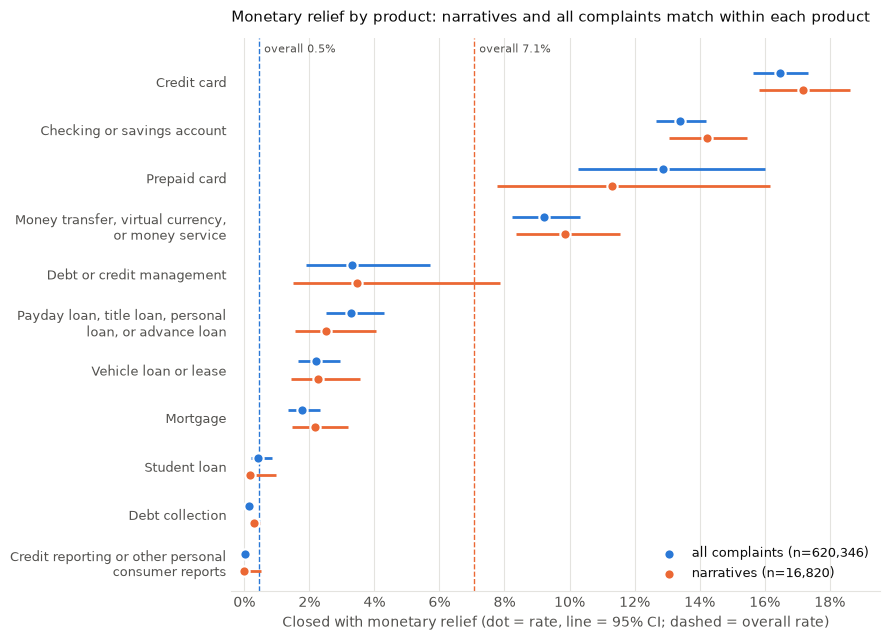

In [10]:
# --- Chart: monetary relief by product -------------------------------------
DODGE = 0.18  # vertical offset within a row so the two CIs don't overlap


def relief_points(df, outcome):
    """Rate of one outcome and its 95% Wilson CI (in %) per product; 'In progress' excluded."""
    closed = df[df[OUTCOME_COL] != "In progress"]
    is_outcome = closed[OUTCOME_COL].eq(outcome).groupby(closed["Product"])
    k, n = is_outcome.sum(), is_outcome.size()
    low, high = wilson_ci(k, n)
    return pd.DataFrame({"n": n, "k": k, "rate": 100 * k / n, "low": 100 * low, "high": 100 * high})


def plot_relief_dots(points, xlabel, title, tick_step):
    """Dot plot per product, one dot + CI per population, sorted by the all-complaints rate (highest on top)."""
    order = points["all complaints"].sort_values("rate").index
    y = np.arange(len(order))

    fig, ax = plt.subplots(figsize=(9, 6.5))
    for offset, (name, pts) in zip([DODGE, -DODGE], points.items()):
        pts = pts.reindex(order)
        color = POP_COLORS[name]
        overall = 100 * pts["k"].sum() / pts["n"].sum()
        ax.axvline(overall, color=color, lw=1, ls="--", zorder=1)
        ax.text(overall + 0.15, len(order) - 0.45, f"overall {overall:.1f}%", color=INK_MUTED, fontsize=8, va="bottom")
        ax.hlines(y + offset, pts["low"], pts["high"], color=color, lw=2, zorder=2)
        ax.scatter(pts["rate"], y + offset, s=55, color=color, edgecolor="white", linewidth=1.5, zorder=3,
                   label=f"{name} (n={pts['n'].sum():,})")

    ax.set_yticks(y, [textwrap.fill(p, 34) for p in order], fontsize=9, color=INK)
    ax.set_ylim(-0.6, len(order) - 0.1)
    ax.set_xlim(-0.4, None)  # just below 0 so dots at 0% aren't clipped
    ax.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(tick_step))
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(decimals=0))
    ax.set_xlabel(f"{xlabel} (dot = rate, line = 95% CI; dashed = overall rate)", color=INK_MUTED)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK_MUTED, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.legend(loc="lower right", frameon=False, fontsize=9, labelcolor=INK)
    ax.set_title(title, loc="left", fontsize=11, color=INK, pad=12)
    fig.tight_layout()
    plt.show()


monetary_points = {name: relief_points(df_pop, MONETARY) for name, df_pop in populations.items()}

# Checks: the plotted numbers must match relief_table(), and each dot must sit inside its CI
results = []
for name, df_pop in populations.items():
    expected = relief_table(df_pop, "Product")
    pts = monetary_points[name].reindex(expected.index)
    rate_diff = (pts["rate"].round(1) - expected["monetary_%"]).abs().max()
    results += [
        check(f"{name}: n per product matches relief_table", (pts["n"] == expected["n"]).all(),
              f"(expected total {expected['n'].sum():,}, actual {pts['n'].sum():,})"),
        check(f"{name}: rate per product matches relief_table", rate_diff == 0,
              f"(max abs difference {rate_diff:.1f} points)"),
        check(f"{name}: every rate inside its CI", pts["rate"].between(pts["low"], pts["high"]).all()),
    ]
assert all(results), "A chart check failed; see the FAIL lines above"

plot_relief_dots(monetary_points, xlabel="Closed with monetary relief", tick_step=2,
                 title="Monetary relief by product: narratives and all complaints match within each product")

**How to read the chart**

- **Dot:** the share of a product's closed complaints that ended in monetary relief (it counts complaints, not dollars). Blue = all complaints, orange = narratives. *Example:* 488 of 2,840 credit-card narratives (17.2%) got monetary relief, vs. 16.5% of all 7,380 closed credit-card complaints.
- **Line through the dot:** the 95% confidence interval, the plausible range given how many complaints the group has. Big groups get short lines, small groups long ones. **If a row's two lines overlap, the data can't tell the two groups apart.**
- **Dashed lines:** each group's overall rate across all products, 0.5% for all complaints (2,855 of 620,346) and 7.1% for narratives (1,190 of 16,820). They are weighted by how many complaints each product has, so they mostly reflect the product mix.
- Gaps are in percentage points: credit card 16.5% vs. mortgage 1.8% is a 14.7-point gap.

**What it shows**

1. **Product drives the rate.** Credit card, checking/savings, prepaid card and money transfer sit at about 9-17%; every other product is under 4%, and credit reporting is about 0%.
2. **Within each product, narratives match all complaints.** In every row the blue and orange CIs overlap. Debt collection overlaps only narrowly (0.15% vs. 0.29%), a gap of about 0.1 points at a very low rate.
3. **The overall gap (0.5% vs. 7.1%) comes from product mix, not from the narrative.** Credit reporting (about 0%) is 91.2% of all closed complaints but only 4.5% of narratives. The four high-relief products are 3.0% of all complaints but 45.6% of narratives. Comparing the dashed lines alone would wrongly suggest narratives are about 14 times more likely to get monetary relief.

**Limits.** The categories are company-reported, and the export has no dollar amounts. For the report, quote narrative relief rates per product, or state that the overall 7.1% reflects the product mix.

##### Chart: Non-Monetary Relief by Product

Same layout as the monetary chart, for `Closed with non-monetary relief`. Each complaint has one closure category, so for every product monetary + non-monetary = any relief; the cell checks that against `relief_table()` before plotting, and lists the products where the two populations' CIs do not overlap.

PASS  all complaints: n per product matches relief_table  (expected total 620,346, actual 620,346)
PASS  all complaints: monetary + non-monetary = any relief  (max abs difference 0.0 points)
PASS  all complaints: every rate inside its CI  
PASS  narratives: n per product matches relief_table  (expected total 16,820, actual 16,820)
PASS  narratives: monetary + non-monetary = any relief  (max abs difference 0.0 points)
PASS  narratives: every rate inside its CI  

CIs that don't overlap (2 of 11 products):
  Credit reporting or other personal consumer reports: all 36.5% (36.4-36.6) vs. narratives 40.9% (37.4-44.4)
  Debt collection: all 26.3% (25.8-26.9) vs. narratives 24.3% (23.2-25.5)


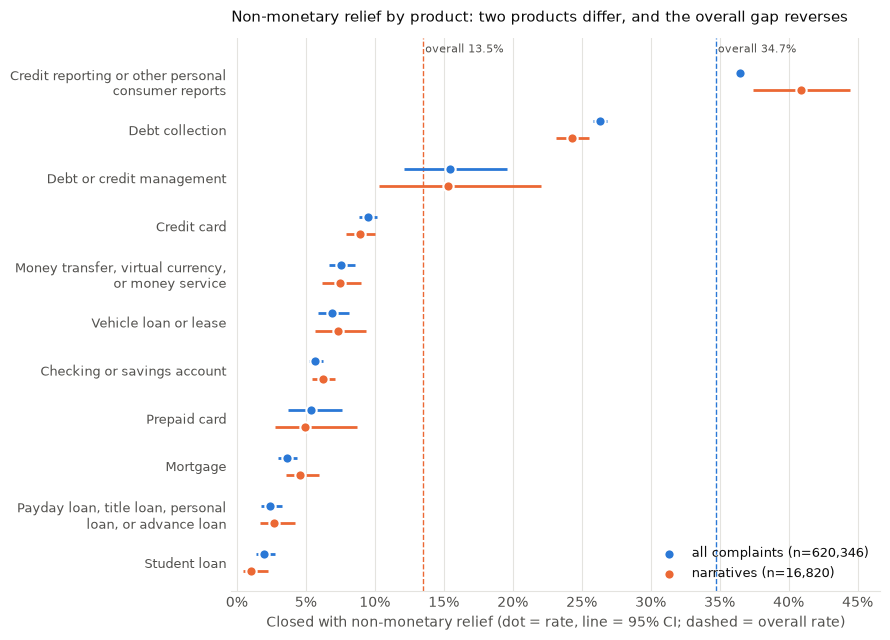

In [11]:
# --- Chart: non-monetary relief by product ---------------------------------
non_monetary_points = {name: relief_points(df_pop, NON_MONETARY) for name, df_pop in populations.items()}

# Checks: n matches relief_table(); monetary + non-monetary counts reproduce its any-relief rate
results = []
for name, df_pop in populations.items():
    expected = relief_table(df_pop, "Product")
    pts = non_monetary_points[name].reindex(expected.index)
    any_k = pts["k"] + monetary_points[name].reindex(expected.index)["k"]
    any_diff = ((100 * any_k / pts["n"]).round(1) - expected["any_relief_%"]).abs().max()
    results += [
        check(f"{name}: n per product matches relief_table", (pts["n"] == expected["n"]).all(),
              f"(expected total {expected['n'].sum():,}, actual {pts['n'].sum():,})"),
        check(f"{name}: monetary + non-monetary = any relief", any_diff == 0,
              f"(max abs difference {any_diff:.1f} points)"),
        check(f"{name}: every rate inside its CI", pts["rate"].between(pts["low"], pts["high"]).all()),
    ]
assert all(results), "A chart check failed; see the FAIL lines above"

# Products where the two populations' CIs don't overlap
all_pts = non_monetary_points["all complaints"]
nar_pts = non_monetary_points["narratives"].reindex(all_pts.index)
no_overlap = (nar_pts["low"] > all_pts["high"]) | (nar_pts["high"] < all_pts["low"])
print(f"\nCIs that don't overlap ({no_overlap.sum()} of {len(no_overlap)} products):")
for product in all_pts.index[no_overlap]:
    a, b = all_pts.loc[product], nar_pts.loc[product]
    print(f"  {product}: all {a['rate']:.1f}% ({a['low']:.1f}-{a['high']:.1f}) "
          f"vs. narratives {b['rate']:.1f}% ({b['low']:.1f}-{b['high']:.1f})")

plot_relief_dots(non_monetary_points, xlabel="Closed with non-monetary relief", tick_step=5,
                 title="Non-monetary relief by product: two products differ, and the overall gap reverses")

**Reading the chart**

Read it like the monetary chart above (same unit, CIs and percentage points). Non-monetary relief means the company reported a concrete, non-cash fix, such as correcting a credit report or stopping collection calls (CFPB definition quoted under Relief Patterns). Because each complaint has one closure category, a product's monetary rate (chart above) plus its non-monetary rate (this chart) is its any-relief rate.

**What it shows**

1. **The overall gap reverses.** Narratives have the *lower* overall rate here: 13.5% (2,272 of 16,820) vs. 34.7% (215,435 of 620,346) for all complaints, the opposite of the monetary chart (7.1% vs. 0.5%). The cause is the same product mix: credit reporting has the highest non-monetary rate and is 91.2% of all closed complaints but only 4.5% of narratives.
2. **Two products differ within the product** (their CIs don't overlap):
   - *Credit reporting*: narratives higher, 40.9% (37.4-44.4) vs. 36.5% (36.4-36.6), a 4.4-point gap.
   - *Debt collection*: narratives lower, 24.3% (23.2-25.5) vs. 26.3% (25.8-26.9), a 2.0-point gap.
3. **The other nine products match**, as in the monetary chart.

**Limits.** The data shows that these two gaps exist, not why. The narrative itself, the kind of issue people write about, or how companies respond to written complaints could each play a part; nothing here separates them.

**Implication.** For both relief types, most of the difference between narratives and all complaints comes from product mix; within products, narratives mostly look like all complaints, except credit reporting and debt collection here. What this means for relief as a target is in the next cell.

##### Why Relief Was Not Chosen as the Target

Four reasons, from the tables and charts above:

1. **The classes do not separate cleanly.** If monetary relief is the thing to predict, every other outcome falls into one "not monetary" class. That class would mix *Closed with non-monetary relief* (the company made a concrete fix) with *Closed with explanation*, which CFPB defines as no relief at all. Two very different outcomes would share one label, and which of the two a complaint gets depends on how the company reports its own response.
2. **One class dominates.** *Closed with explanation* is 76.5% of narratives (Target Candidates table above), and monetary relief is 7.1% (1,190 of 16,820). A model that always predicts "no relief" would look accurate without reading anything.
3. **The structured fields already explain most of it.** Product drives the relief rate: monetary relief is about 9-17% for credit card, checking/savings, prepaid card and money transfer, under 4% for the other products, and about 0% for credit reporting. The company matters too: among narratives, Bank of America gave monetary relief in 35.9% of complaints and Wells Fargo in 13.0%. Most of the answer is known before anyone reads the narrative.
4. **Having a narrative makes little difference.** Within a product, complaints with a narrative get relief at about the same rate as all complaints. For monetary relief, every product's confidence intervals overlap; for non-monetary relief, only credit reporting (+4.4 points) and debt collection (-2.0 points) differ. The overall gaps come from product mix.

**Next:** the three remaining candidates, labels the consumer picks to describe their own complaint, so the narrative itself should carry the signal.

#### Candidates 2-4: Product, Sub-product and Issue

With relief set aside, the search moves to the three labels the consumer picks when filing: Product first, then a Sub-product and an Issue from the options that Product offers. Each describes *what the complaint is about*, which is what the narrative is written to explain. The practical question: does each class have enough narratives to train and score a model?

##### Chart: Class Sizes per Target Candidate

One panel per candidate, one dot per class, on a log scale; dashed lines mark `MIN_CLASS_SMALL` (30) and `MIN_CLASS_LARGE` (100) narratives. Counts include duplicate narratives; the deduplicated Issue counts are in Clean > Modeling Set: Issue Class Sizes.

PASS  Product: classes / >=30 / >=100 match the table  (expected (11, 11, 11), actual (11, 11, 11))
PASS  Product: classes add up to all narratives  (16,820 of 16,820)
PASS  Sub-product: classes / >=30 / >=100 match the table  (expected (52, 37, 26), actual (52, 37, 26))
PASS  Sub-product: classes add up to all narratives  (16,820 of 16,820)
PASS  Issue: classes / >=30 / >=100 match the table  (expected (83, 53, 38), actual (83, 53, 38))
PASS  Issue: classes add up to all narratives  (16,820 of 16,820)


,classes >=100,narratives >=100,% >=100,classes 30-99,narratives 30-99,% 30-99,classes <30,narratives <30,% <30
Product,11.0,16820.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0
Sub-product,26.0,15927.0,94.7,11.0,673.0,4.0,15.0,220.0,1.3
Issue,38.0,15683.0,93.2,15.0,886.0,5.3,30.0,251.0,1.5


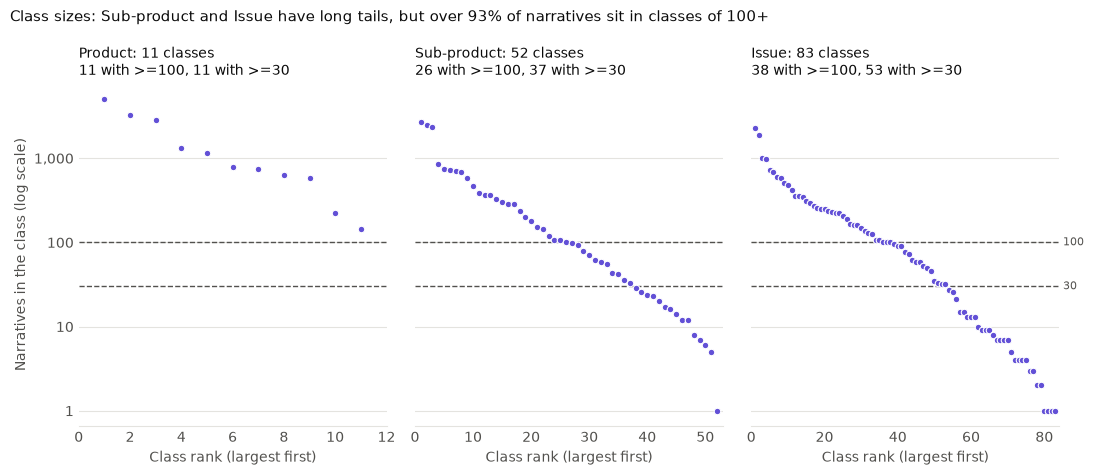

In [12]:
# --- Chart: class sizes per target candidate --------------------------------
CLASS_TARGETS = ["Product", "Sub-product", "Issue"]  # Company response is an outcome, not a "what is it about" label
CLASS_COLOR = "#6250d6"  # palette slot 7; blue/orange stay reserved for all complaints vs. narratives

class_sizes = {col: df_narrative[col].value_counts() for col in CLASS_TARGETS}

# Checks: class counts match the Target Candidates table, and each target's classes cover every narrative
results = []
for col, vc in class_sizes.items():
    row = targets.loc[col]
    expected = (int(row["classes"]), int(row[f"classes_>={MIN_CLASS_SMALL}"]), int(row[f"classes_>={MIN_CLASS_LARGE}"]))
    actual = (len(vc), int((vc >= MIN_CLASS_SMALL).sum()), int((vc >= MIN_CLASS_LARGE).sum()))
    results += [
        check(f"{col}: classes / >=30 / >=100 match the table", actual == expected, f"(expected {expected}, actual {actual})"),
        check(f"{col}: classes add up to all narratives", vc.sum() == len(df_narrative), f"({vc.sum():,} of {len(df_narrative):,})"),
    ]
assert all(results), "A chart check failed; see the FAIL lines above"

# How many classes, and narratives, sit in each class-size band (band_summary is reused in Clean)
def band_summary(vc: pd.Series) -> dict:
    """Classes and narratives in each class-size band."""
    bands_ = {">=100": vc >= MIN_CLASS_LARGE, "30-99": vc.between(MIN_CLASS_SMALL, MIN_CLASS_LARGE - 1), "<30": vc < MIN_CLASS_SMALL}
    out = {}
    for name, mask in bands_.items():
        out[f"classes {name}"] = int(mask.sum())
        out[f"narratives {name}"] = int(vc[mask].sum())
        out[f"% {name}"] = round(100 * vc[mask].sum() / vc.sum(), 1)
    return out


bands = pd.DataFrame({col: band_summary(vc) for col, vc in class_sizes.items()}).T
display(bands)

# Plot: one panel per target, shared log y-axis
fig, axes = plt.subplots(1, 3, figsize=(11, 4.8), sharey=True)
for ax, (col, vc) in zip(axes, class_sizes.items()):
    rank = np.arange(1, len(vc) + 1)
    ax.scatter(rank, vc.values, s=22, color=CLASS_COLOR, edgecolor="white", linewidth=0.8, zorder=3)
    for threshold in [MIN_CLASS_SMALL, MIN_CLASS_LARGE]:
        ax.axhline(threshold, color=INK_MUTED, lw=1, ls="--", zorder=1)
    n30, n100 = int((vc >= MIN_CLASS_SMALL).sum()), int((vc >= MIN_CLASS_LARGE).sum())
    ax.set_title(f"{col}: {len(vc)} classes\n{n100} with >=100, {n30} with >=30", loc="left", fontsize=10, color=INK)
    ax.set_yscale("log")
    ax.set_xlim(0, len(vc) + 1)
    ax.set_xlabel("Class rank (largest first)", color=INK_MUTED)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(which="both", colors=INK_MUTED, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

axes[0].yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].set_ylabel("Narratives in the class (log scale)", color=INK_MUTED)
for threshold in [MIN_CLASS_SMALL, MIN_CLASS_LARGE]:
    axes[-1].text(axes[-1].get_xlim()[1], threshold, f" {threshold}", va="center", ha="left", fontsize=8, color=INK_MUTED)
fig.suptitle("Class sizes: Sub-product and Issue have long tails, but over 93% of narratives sit in classes of 100+", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
plt.show()

**How to read the chart**

- **Each dot is one class** (e.g. one Issue), ranked from largest (left) to smallest (right). Its height is how many narratives carry that label.
- **Log scale:** each gridline is 10 times the one below (1, 10, 100, 1,000), so classes of 5 narratives stay visible next to classes of thousands.
- **Dashed lines at 30 and 100** mark how much data a class needs to be scored on its own. A test set gets only part of each class, and small samples give wide confidence intervals: 80% recall measured on 6 test examples has a 95% CI of about 44-97%, on 30 examples about 63-90%. So under 30 a class can't be scored reliably, 30-99 can be scored with wide CIs, and 100+ can be scored on its own. These are rules of thumb, not fixed standards.

**What it shows** (from the table above the chart)

1. **Product:** all 11 classes have at least 100 narratives (smallest: 144), so every class can be scored.
2. **Sub-product:** 26 of 52 classes have 100+, holding 15,927 narratives (94.7%). The 15 classes under 30 hold only 220 narratives (1.3%).
3. **Issue:** 38 of 83 classes have 100+, holding 15,683 narratives (93.2%). The 30 classes under 30 hold only 251 narratives (1.5%).
4. **The long tails are thin.** Sub-product and Issue have many small classes, but those classes hold few narratives.

**Decision: Issue is the target.** It is the label that best fits a model reading the narrative:
- **Most specific.** Product names the kind of account ("Debt collection"); Issue names what went wrong ("Attempts to collect debt not owed"), which is what a narrative is written to explain.
- **Enough data to score.** Its 38 classes of 100+ hold 93.2% of narratives; the 30 classes under 30 hold only 1.5%.

All 83 Issues stay as classes, with no merging into "Other": Issue options depend on Product and Sub-product, so merging or dropping rare classes would remove options consumers actually see.

### Duplicate Narratives

Some narratives appear more than once. Copies that land in both the training and the test set let the baseline score on text it has already seen, so its results would look better than they are. Two types turn up in the 16,820 narratives:
- **Type 1: the same text filed more than once.** Copies count as the same text after ignoring punctuation and capitals.
- **Type 2: a template.** One script copied over and over with only the collector's name and the account number changed, so the copies are not identical text.

**Result:** both types are removed in Clean, leaving 15,176 narratives for modeling, still covering all 83 Issues.

#### Type 1: The Same Text Filed More Than Once

Two narratives are copies when their whole text matches after normalizing: lowercase, punctuation turned into spaces, whitespace collapsed. Redaction marks (XXXX) stay, because CFPB applies them to every narrative. The normalized form is used only for matching; the models read the original text.

In [13]:
# --- Duplicates, Type 1: the same text filed more than once -----------------
# Clean reuses comparison_key().
def comparison_key(text: pd.Series) -> pd.Series:
    """Lowercase, punctuation to spaces, collapse whitespace, trim. Redaction marks (XXXX) are kept."""
    return (text.str.lower()
                .str.replace(r"[^\w\s]", " ", regex=True)
                .str.replace(r"\s+", " ", regex=True)
                .str.strip())


texts = df_narrative[NARRATIVE_COL]
narr_key = comparison_key(texts)
exact_extra = int(texts.duplicated().sum())
key_extra = int(narr_key.duplicated().sum())
expected_exact = len(texts) - int(profile.loc[NARRATIVE_COL, "n_unique"])

results = [
    check("exact copies match the structure profile", exact_extra == expected_exact,
          f"(expected {expected_exact:,}, actual {exact_extra:,})"),
    check("normalizing never finds fewer copies", key_extra >= exact_extra, f"(exact {exact_extra:,}, normalized {key_extra:,})"),
    check("no empty keys", (narr_key != "").all(), f"(empty: {(narr_key == '').sum():,})"),
]
assert all(results), "A duplicate check failed; see the FAIL lines above"

print(f"\nExtra copies, exact text:        {exact_extra:,}")
print(f"Extra copies, after normalizing: {key_extra:,} ({100 * key_extra / len(texts):.1f}% of {len(texts):,} narratives)")


def first_difference(a: str, b: str, width: int = 25) -> str:
    """Both texts around the first character where they differ."""
    i = next((k for k, (x, y) in enumerate(zip(a, b)) if x != y), min(len(a), len(b)))
    lo = max(0, i - width)
    return f"{a[lo:i + width]!r}  vs.  {b[lo:i + width]!r}"


# What normalizing adds: texts that differ only in punctuation or capitals
variants = texts.groupby(narr_key).agg(copies="size", raw_texts="nunique")
merged = variants[variants["raw_texts"] > 1].sort_values("copies", ascending=False)
examples = []
for key in merged.index:   # three different kinds of difference, from the most-copied texts
    a, b = sorted(texts[narr_key == key].unique()[:2], key=len)
    diff = first_difference(a, b)
    if diff not in examples:
        examples.append(diff)
    if len(examples) == 3:
        break
print(f"\nNormalizing merges {len(merged):,} groups of slightly different texts, for example:")
for diff in examples:
    print("  ", diff)

# The largest groups: how many copies, and across how many companies
groups = df_narrative.groupby(narr_key).agg(copies=("Complaint ID", "size"), companies=("Company", "nunique"),
                                             issues=("Issue", "nunique"))
repeated = groups[groups["copies"] > 1]
print(f"\nTexts that repeat: {len(repeated):,}, covering {repeated['copies'].sum():,} narratives")
largest = repeated.sort_values("copies", ascending=False).head(5).reset_index(drop=True)
largest["starts_with"] = [texts[narr_key == k].iloc[0][:70] for k in
                          repeated.sort_values("copies", ascending=False).head(5).index]
display(largest)

# Do the copies of a text agree on Issue?
disagree = int((repeated["issues"] > 1).sum())
print(f"Repeated texts whose copies disagree on Issue: {disagree} of {len(repeated):,}")

PASS  exact copies match the structure profile  (expected 1,440, actual 1,440)
PASS  normalizing never finds fewer copies  (exact 1,440, normalized 1,488)
PASS  no empty keys  (empty: 0)

Extra copies, exact text:        1,440
Extra copies, after normalizing: 1,488 (8.8% of 16,820 narratives)

Normalizing merges 44 groups of slightly different texts, for example:
   'gnificant stress and XXXX affecting my mental heal'  vs.  'gnificant stress and XXXX, affecting my mental hea'
   'edit!! Account number is XXXX is falsely reporting'  vs.  'edit!! Account number is # XXXX is falsely reporti'
   'ile a complaint against JEFFERSON CAPITAL LLC for '  vs.  'ile a complaint against Jefferson Capital, LLC for'

Texts that repeat: 329, covering 1,817 narratives


,copies,companies,issues,starts_with
0,278,93,1,This debt collector has engaged in conduct that violates the Fair Debt
1,194,3,1,There are collection accounts on my report that I believe contain inac
2,96,47,1,I am writing to formally request debt validation for a collection acco
3,45,31,1,I am formally disputing the validity of the alleged collection and cha
4,31,18,1,Delete this account because you can not furnish any documentation that


Repeated texts whose copies disagree on Issue: 14 of 329


**Findings**
- **1,440 extra copies of exact text**; normalizing adds 48 more that differ only by a comma, a "#" before a redaction mark, or capitals: **1,488 in all (8.8% of narratives)**.
- The largest groups run to hundreds of copies across dozens of companies (the top text: 278 copies, 93 companies), so some texts look like shared scripts rather than one person's complaint.
- Copies almost always agree on Issue: 14 of 329 repeated texts disagree.

#### Type 2: The Template Family

One script recurs with only the collector's name and the redacted account number changed, so Type 1 cannot merge the copies:

> *"[collector] is falsely reporting on my credit. I have never had any accounts with them. Per my research [collector] is a debt collector..."*

A narrative belongs to the family when it contains at least 2 of the script's 4 fixed sentences (2, not 4, because some copies have typos or are cut off).

In [14]:
# --- Duplicates, Type 2: the template family -------------------------------
# Clean reuses these definitions.
# The script's four fixed sentences, in comparison-key form (lowercase, no punctuation)
TEMPLATE_SIGNATURES = [
    "is falsely reporting on my credit i have never had any accounts with them",
    "is a debt collector they are falsely reporting on my credit",
    "is falsely reporting to my credit file and is against my rights and fair credit act",
    "of investigation consumer report you are in violation",
]
TEMPLATE_MIN_HITS = 2  # 2 of 4 tolerates the typos and cut-off text seen in some copies


def template_signature_hits(key: pd.Series) -> pd.Series:
    """Number of template sentences each comparison key contains (0 to len(TEMPLATE_SIGNATURES))."""
    return sum(key.str.contains(sig, regex=False).astype(int) for sig in TEMPLATE_SIGNATURES)


template_hits = template_signature_hits(narr_key)
is_template = template_hits >= TEMPLATE_MIN_HITS
family_rows = df_narrative[is_template]
n_partial = int(template_hits.between(1, TEMPLATE_MIN_HITS - 1).sum())

results = [
    check("family found", is_template.any(),
          f"({len(family_rows):,} complaints, {narr_key[is_template].nunique():,} different texts after normalizing)"),
    check("no narrative sits just below the threshold", n_partial == 0, f"(expected 0, actual {n_partial:,})"),
]
assert all(results), "A template-family check failed; see the FAIL lines above"
print("Fixed sentences matched per complaint:", template_hits[is_template].value_counts().sort_index().to_dict())

# Two copies: the same script with a different collector's name
print()
for key in narr_key[is_template].value_counts().index[:2]:
    print(textwrap.fill(texts[narr_key == key].iloc[0], width=110), "\n")

# Same labels, different filers
cols = ["Product", "Sub-product", "Issue", "Sub-issue", "Submitted via", "Company", "State", "ZIP code", "Date received"]
family_profile = pd.DataFrame({
    "distinct values": family_rows[cols].nunique(),
    "most common": family_rows[cols].mode().iloc[0],
    "most common %": (100 * family_rows[cols].apply(lambda s: s.value_counts().iloc[0]) / len(family_rows)).round(1),
})
display(family_profile)

PASS  family found  (322 complaints, 149 different texts after normalizing)
PASS  no narrative sits just below the threshold  (expected 0, actual 0)
Fixed sentences matched per complaint: {2: 1, 3: 13, 4: 308}

CREDIT COLL is falsely reporting on my credit. I have never had any accounts with them. Per my research CREDIT
COLL is a debt collector. They are falsely reporting on my credit!! Account number is # XXXX is falsely
reporting to my credit file and is against my rights and fair credit act. Under U.S Code 1618d - Disclosure of
investigation consumer report ; you are in violation. 

JEFFCAPSYS is falsely reporting on my credit. I have never had any accounts with them. Per my research
JEFFCAPSYS is a debt collector. They are falsely reporting on my credit!! Account number is XXXX is falsely
reporting to my credit file and is against my rights and fair credit act. Under U.S Code 1618d - Disclosure of
investigation consumer report ; you are in violation. 



,distinct values,most common,most common %
Product,1,Debt collection,100.0
Sub-product,1,I do not know,100.0
Issue,1,Attempts to collect debt not owed,100.0
Sub-issue,2,Debt was result of identity theft,99.4
Submitted via,1,Web,100.0
Company,28,CL Holdings LLC,22.0
State,27,FL,21.4
ZIP code,186,61821,4.0
Date received,20,2026-06-09,14.6


**Findings**
- **322 complaints (149 different texts, 1.9% of narratives)** follow the script.
- **The labels are identical:** all are Debt collection / Sub-product "I do not know" / Issue "Attempts to collect debt not owed", and 99.4% have Sub-issue "Debt was result of identity theft". All came through the web form.
- **The filers are not:** 186 ZIP codes, 27 states, 28 companies and 20 filing dates. A single filer is unlikely; an advocacy group or credit-repair service handing out a script would fit, but the data cannot say who wrote it.

#### Decision

Clean applies these rules to the narratives and logs every drop:
1. **Template family: drop every copy.** Keeping one copy per variant would still leave many near-identical texts with one shared label, which would give the baseline easy answers if they split across train and test.
2. **Copies that disagree on Issue: keep the majority Issue**, and drop the text on a tie (7 texts). The same words carry different labels, so the label a model learns from them is uncertain.
3. **All other copies: keep one per normalized text**, the first in file order.

**Result:** 15,176 narratives for modeling, still covering all 83 Issues. The Explore sections above keep every row, since each complaint is a real filing.

**Limitations.** Only this one template was searched for by its wording. Other scripts that vary in more than formatting would survive as separate narratives; similarity matching (e.g. TF-IDF cosine) could look for them.

## Clean

`clean_ccdb()` builds the modeling set, `df_clean`, from the raw export in one function, so it can be rerun on another export. `df_raw` is never modified. Three stages:
1. **Rows:** narratives only, then the duplicate rules from *Duplicate Narratives > Decision*.
2. **Columns:** only the columns the models need, each with a role (`COLUMN_ROLES`):

| Role | Columns | Why |
|---|---|---|
| id | Complaint ID | join key |
| input | narrative | what both models read |
| target | Issue | what they predict |
| context | Product, Sub-product | given to the LLM with the narrative |
| subgroup | Company, State, Date received, Older American, Servicemember | for the sub-group evaluation |

   Dropped: Sub-issue, a finer split of Issue chosen after it, would give the target away; Company response to consumer, Company public response, Timely response? and Date sent to company are known only after the company responds. Any of them can be added back if the evaluation needs it.
3. **Types:** label columns become categories; the narrative stays text.

PENDING: State codes beyond the 50 states + DC; narrative length.

In [15]:
# --- Cleaning pipeline -----------------------------------------------------
# Every column the modeling set keeps, and its role (Older American / Servicemember are split out of Tags)
COLUMN_ROLES = {
    "Complaint ID": "id",
    "Consumer complaint narrative": "input",
    "Issue": "target",
    "Product": "context",
    "Sub-product": "context",
    "Company": "subgroup",
    "State": "subgroup",
    "Date received": "subgroup",
    "Older American": "subgroup",
    "Servicemember": "subgroup",
}
CATEGORY_COLS = ["Issue", "Product", "Sub-product", "Company", "State"]


def clean_ccdb(raw):
    """Build the modeling set from a raw CCDB export read with dtype=str.

    Returns (cleaned DataFrame, row funnel). The input is not modified.
    """
    funnel = [("raw export", len(raw))]

    # 1. Rows: narratives only, then the duplicate rules (Explore > Duplicate Narratives > Decision)
    df = raw[raw[NARRATIVE_COL].fillna("").str.strip() != ""].copy()
    funnel.append(("narratives only", len(df)))
    key = comparison_key(df[NARRATIVE_COL]).rename("key")

    template = template_signature_hits(key) >= TEMPLATE_MIN_HITS
    df, key = df[~template], key[~template]
    funnel.append(("template family", len(df)))

    votes = pd.crosstab(key, df["Issue"])                       # one row per text: copies per Issue
    is_tie = votes.eq(votes.max(axis=1), axis=0).sum(axis=1) > 1  # two or more Issues share the top count
    tied = key.map(is_tie)
    df, key = df[~tied], key[~tied]
    funnel.append(("Issue ties", len(df)))

    minority = df["Issue"] != key.map(votes.idxmax(axis=1))     # copy outvoted by its text's majority Issue
    df, key = df[~minority], key[~minority]
    funnel.append(("minority Issue", len(df)))

    df = df[~key.duplicated(keep="first")]                       # one copy per text, first in file order
    funnel.append(("duplicate texts", len(df)))

    # 2. Columns: Tags -> two yes/no flags, Date received -> datetime, keep only the role columns
    tags = df["Tags"].fillna("")
    unknown_tags = set(tags.str.split(", ").explode()) - {"", "Older American", "Servicemember"}
    assert not unknown_tags, f"Unexpected Tags values: {unknown_tags}"
    df["Older American"] = tags.str.contains("Older American", regex=False)
    df["Servicemember"] = tags.str.contains("Servicemember", regex=False)
    df["Date received"] = pd.to_datetime(df["Date received"], format="%Y-%m-%d")  # stops on any other format
    df = df[list(COLUMN_ROLES)]

    # 3. Types: label columns become categories; the narrative stays text
    df[CATEGORY_COLS] = df[CATEGORY_COLS].astype("category")

    funnel = pd.DataFrame(funnel, columns=["step", "rows left"])
    funnel["dropped"] = (-funnel["rows left"].diff()).astype("Int64")
    return df, funnel

In [16]:
# --- Run cleaning + checks -------------------------------------------------
df_clean, funnel = clean_ccdb(df_raw)
display(funnel)

# The rules restated from the Explore variables (narr_key, is_template), to check df_clean against
explore_key, explore_issue = narr_key[~is_template], df_narrative.loc[~is_template, "Issue"]
votes = pd.crosstab(explore_key, explore_issue)
tied_texts = votes.index[votes.eq(votes.max(axis=1), axis=0).sum(axis=1) > 1]
clean_key = comparison_key(df_clean[NARRATIVE_COL])
received = df_clean["Date received"]
step = funnel.set_index("step")

results = [
    check("narratives match Explore", step.loc["narratives only", "rows left"] == len(df_narrative),
          f"(expected {len(df_narrative):,}, actual {step.loc['narratives only', 'rows left']:,})"),
    check("template rows dropped match Explore", step.loc["template family", "dropped"] == is_template.sum(),
          f"(expected {is_template.sum():,}, actual {step.loc['template family', 'dropped']:,})"),
    check("every non-template text kept once, except Issue ties",
          set(clean_key) == set(explore_key) - set(tied_texts) and clean_key.is_unique,
          f"(expected {explore_key.nunique() - len(tied_texts):,}, actual {len(df_clean):,})"),
    check("each kept text has its majority Issue",
          (df_clean["Issue"].astype(str).values == votes.idxmax(axis=1).reindex(clean_key).values).all()),
    check("no template narratives remain", (template_signature_hits(clean_key) < TEMPLATE_MIN_HITS).all()),
    check("Complaint ID unique", df_clean["Complaint ID"].is_unique),
    check("Date received within June 2026", received.between("2026-06-01", "2026-06-30").all(),
          f"({received.min():%Y-%m-%d} to {received.max():%Y-%m-%d})"),
    check("columns match COLUMN_ROLES", list(df_clean.columns) == list(COLUMN_ROLES)),
    check("df_raw untouched", list(df_raw.columns) == EXPECTED_COLS and len(df_raw) == 620_794),
]
assert all(results), "A cleaning check failed; see the FAIL lines above"

print(f"\nModeling set: {len(df_clean):,} narratives, {df_clean['Issue'].nunique():,} Issue classes, "
      f"{df_clean.shape[1]} columns")

,step,rows left,dropped
0,raw export,620794,<NA>
1,narratives only,16820,603974
2,template family,16498,322
3,Issue ties,16482,16
4,minority Issue,16474,8
5,duplicate texts,15176,1298


PASS  narratives match Explore  (expected 16,820, actual 16,820)
PASS  template rows dropped match Explore  (expected 322, actual 322)
PASS  every non-template text kept once, except Issue ties  (expected 15,176, actual 15,176)
PASS  each kept text has its majority Issue  
PASS  no template narratives remain  
PASS  Complaint ID unique  
PASS  Date received within June 2026  (2026-06-01 to 2026-06-30)
PASS  columns match COLUMN_ROLES  
PASS  df_raw untouched  

Modeling set: 15,176 narratives, 83 Issue classes, 10 columns


### Modeling Set: Issue Class Sizes

Issue is the target (decided 2026-11-03). The Target Candidates chart counted every narrative, duplicates included; this chart repeats the Issue panel on `df_clean`, the deduplicated modeling set, with the earlier count shown for comparison. Same thresholds: `MIN_CLASS_SMALL` (30) and `MIN_CLASS_LARGE` (100).

PASS  before matches the Target Candidates table  (classes: 83)
PASS  after adds up to the modeling set  (expected 15,176, actual 15,176)
PASS  no class grows  (min dropped: 0)


,classes >=100,narratives >=100,% >=100,classes 30-99,narratives 30-99,% 30-99,classes <30,narratives <30,% <30
all narratives,38,15683,93.2,15,886,5.3,30,251,1.5
modeling set,38,14049,92.6,15,884,5.8,30,243,1.6


Largest drops:


,before,after,dropped,dropped_%
Issue,,,,
Attempts to collect debt not owed,2297,1659,638,27.8
Written notification about debt,974,652,322,33.1
Took or threatened to take negative or legal action,688,373,315,45.8
Incorrect information on your report,587,432,155,26.4
Improper use of your report,251,154,97,38.6


Classes under 30 in the modeling set (30):


,before,after,dropped,dropped_%
Issue,,,,
Can't stop withdrawals from your bank account,27,27,0,0.0
Confusing or misleading advertising or marketing,26,26,0,0.0
Credit monitoring or identity theft protection services,21,19,2,9.5
Wrong amount charged or received,15,15,0,0.0
Can't contact lender or servicer,13,13,0,0.0
Charged upfront or unexpected fees,13,13,0,0.0
Getting a line of credit,13,13,0,0.0
Problem with fraud alerts or security freezes,15,10,5,33.3
Unauthorized withdrawals or charges,10,10,0,0.0


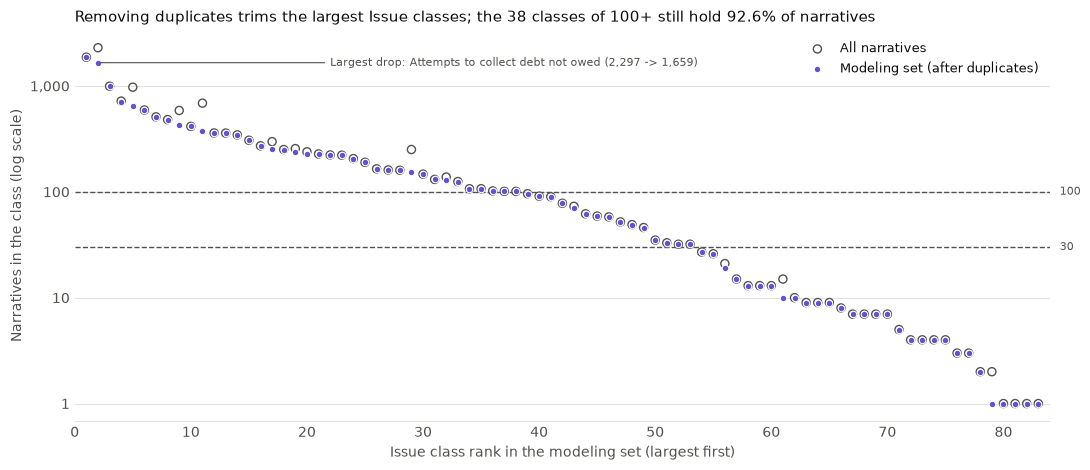

In [17]:
# --- Chart: Issue class sizes in the modeling set -----------------------------
# Same thresholds as the Target Candidates chart; "before" = all narratives, "after" = df_clean.
issue_before = df_narrative["Issue"].value_counts()
issue_after = df_clean["Issue"].value_counts()
issue_after = issue_after[issue_after > 0]  # a category column also lists empty categories

issue_sizes = (pd.DataFrame({"before": issue_before, "after": issue_after}).fillna(0).astype(int)
               .sort_values(["after", "before"], ascending=False))
issue_sizes["dropped"] = issue_sizes["before"] - issue_sizes["after"]
issue_sizes["dropped_%"] = (100 * issue_sizes["dropped"] / issue_sizes["before"]).round(1)

results = [
    check("before matches the Target Candidates table",
          (len(issue_before), int((issue_before >= MIN_CLASS_SMALL).sum()), int((issue_before >= MIN_CLASS_LARGE).sum()))
          == (int(targets.loc["Issue", "classes"]), int(targets.loc["Issue", f"classes_>={MIN_CLASS_SMALL}"]),
              int(targets.loc["Issue", f"classes_>={MIN_CLASS_LARGE}"])),
          f"(classes: {len(issue_before)})"),
    check("after adds up to the modeling set", issue_after.sum() == len(df_clean),
          f"(expected {len(df_clean):,}, actual {issue_after.sum():,})"),
    check("no class grows", (issue_sizes["dropped"] >= 0).all(), f"(min dropped: {issue_sizes['dropped'].min()})"),
]
assert all(results), "A chart check failed; see the FAIL lines above"


# band_summary() is defined in the Target Candidates class-size chart
issue_bands = pd.DataFrame([band_summary(issue_before), band_summary(issue_after)], index=["all narratives", "modeling set"])
display(issue_bands)

# Classes that lost the most narratives, and every class under 30 in the modeling set
print("Largest drops:")
display(issue_sizes.sort_values("dropped", ascending=False).head(5))
print(f"Classes under {MIN_CLASS_SMALL} in the modeling set ({(issue_sizes['after'] < MIN_CLASS_SMALL).sum()}):")
display(issue_sizes[issue_sizes["after"] < MIN_CLASS_SMALL])

# Plot: modeling-set count per class (violet), with the all-narratives count as a hollow gray ring
rank = np.arange(1, len(issue_sizes) + 1)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.scatter(rank, issue_sizes["before"], s=34, facecolor="none", edgecolor=INK_MUTED, linewidth=1, zorder=2,
           label="All narratives")
ax.scatter(rank, issue_sizes["after"], s=22, color=CLASS_COLOR, edgecolor="white", linewidth=0.8, zorder=3,
           label="Modeling set (after duplicates)")
for threshold in [MIN_CLASS_SMALL, MIN_CLASS_LARGE]:
    ax.axhline(threshold, color=INK_MUTED, lw=1, ls="--", zorder=1)
    ax.text(len(issue_sizes) + 1.5, threshold, f" {threshold}", va="center", ha="left", fontsize=8, color=INK_MUTED)

top_drop = issue_sizes["dropped"].idxmax()
r = issue_sizes.index.get_loc(top_drop) + 1
ax.annotate(f"Largest drop: {top_drop} ({issue_sizes.loc[top_drop, 'before']:,} -> {issue_sizes.loc[top_drop, 'after']:,})",
            (r, issue_sizes.loc[top_drop, "after"]), xytext=(22, issue_sizes.loc[top_drop, "after"]), textcoords="data",
            va="center", fontsize=8, color=INK_MUTED, arrowprops={"arrowstyle": "-", "color": INK_MUTED, "lw": 0.8})

ax.set_yscale("log")
ax.set_xlim(0, len(issue_sizes) + 1)
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Issue class rank in the modeling set (largest first)", color=INK_MUTED)
ax.set_ylabel("Narratives in the class (log scale)", color=INK_MUTED)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(which="both", colors=INK_MUTED, length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.legend(frameon=False, loc="upper right", fontsize=9, labelcolor=INK)
ax.set_title(f"Removing duplicates trims the largest Issue classes; the {issue_bands.loc['modeling set', 'classes >=100']} classes "
             f"of 100+ still hold {issue_bands.loc['modeling set', '% >=100']}% of narratives", loc="left", fontsize=11, color=INK)
fig.tight_layout()
plt.show()

**Reading the chart**

- **One column per Issue class**, ranked by its size in the modeling set (largest on the left), on the same log scale as the Target Candidates chart.
- **Violet dot:** narratives in the modeling set. **Gray ring:** narratives before removing duplicates. Where the ring sits above the dot, that class lost copies; where they overlap, it lost none.
- **Dashed lines** at 30 and 100 narratives, the same scoring thresholds as before.

**What it shows** (from the tables above the chart)

1. **The bands did not change:** 38 classes still have 100+ narratives (14,049, 92.6% of the modeling set), 15 have 30-99 (884, 5.8%), and 30 have under 30 (243, 1.6%).
2. **The drops sit in a few large classes,** mostly debt collection. *Attempts to collect debt not owed* lost 638 (27.8%, including the 322 template complaints), *Written notification about debt* 322 (33.1%), and *Took or threatened to take negative or legal action* 315 (45.8%). Two credit-reporting classes follow: *Incorrect information on your report* (155) and *Improper use of your report* (97).
3. **The tail is almost untouched.** The 30 classes under 30 narratives held 251 narratives before removing duplicates and 243 after. 27 of them lost none, because their narratives are unique with no exact copies.

Decision: all 83 Issues stay in the modeling set, with no merging into "Other". Issue options depend on Product and Sub-product, so dropping rare classes would delete options consumers actually see (for Payday loans, 18 of 28). Rare classes are examined in the sub-group evaluation, after the overall results.

### Schema Check and Data Dictionary Export

PENDING: once cleaning decisions are final, assert the expected dtype of every column in `df_clean` (PASS/FAIL), then write the column / role / dtype / null_% / CFPB description table between the markers in `data/README.md`.